In [11]:
# Part 0 — Setup and the Data
# Task 1: Install and import
# !pip install imbalanced-learn
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_val_predict, learning_curve)
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42



In [4]:
# Task 2: Load and explore
df = pd.read_csv(r"C:\Users\M.LAPTOP\Desktop\ml lab9\healthcare-dataset-stroke-data_1.csv")
print("Shape:", df.shape)
missing = df.isnull().sum()
print("\nMissing values:\n", missing[missing > 0])
print("\nGender counts:\n", df["gender"].value_counts())
counts = df["stroke"].value_counts()
percent = (df["stroke"].value_counts(normalize=True) * 100).round(2)
print("\nStroke:\n", pd.DataFrame({"count": counts, "percent (%)": percent}))



Shape: (5110, 12)

Missing values:
 bmi    201
dtype: int64

Gender counts:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke:
         count  percent (%)
stroke                    
0        4861        95.13
1         249         4.87


In [5]:
# Task 3: Clean
df = df.drop(columns=["id"])
gc = df["gender"].value_counts()
rare = gc[gc < 10].index
df = df[~df["gender"].isin(rare)].reset_index(drop=True)
text_cols = df.select_dtypes(exclude="number").columns.tolist()
df = pd.get_dummies(df, columns=text_cols, drop_first=True, dtype=int)
print(df.shape)

(5109, 16)


In [6]:
# Task 4: Split, impute and scale
X = df.drop(columns="stroke"); y = df["stroke"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

med = X_train.median()                      # learned from TRAIN only
X_train = X_train.fillna(med); X_test = X_test.fillna(med)

scaler = StandardScaler().fit(X_train)      # fitted on TRAIN only
X_train_sc = pd.DataFrame(scaler.transform(X_train), columns=X.columns, index=X_train.index)
X_test_sc  = pd.DataFrame(scaler.transform(X_test),  columns=X.columns, index=X_test.index)

In [7]:
# Task 5: Stroke counts.
print("Train:", y_train.sum(), "of", len(y_train), f"({y_train.mean()*100:.2f}%)")
print("Test: ", y_test.sum(),  "of", len(y_test),  f"({y_test.mean()*100:.2f}%)")

Train: 199 of 4087 (4.87%)
Test:  50 of 1022 (4.89%)


In [8]:
# Question (a) In 2-3 lines: how imbalanced is the data? Why did we use stratify=y, and what could go wrong with only a 
# few stroke cases in the test set?
# about 1 stroke per 20 patients. stratify=y keeps the stroke rate the same in train and test. With only a few test strokes, 
# recall and AUC become very unstable, since one patient moves recall a lot. Even now there are only 50.

In [9]:
# Part 1 — The Accuracy Trap
# Show that a model can have excellent accuracy and still be useless. 
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {"Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred, zero_division=0),
            "Recall": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred),
            "ROC AUC": roc_auc_score(y_te, proba),
            "PR AUC": average_precision_score(y_te, proba)}

In [10]:
# Task 1: Baseline.Always predict the majority class.

dummy_m = evaluate_model(DummyClassifier(strategy="most_frequent"), X_train, y_train, X_test, y_test)
print("Baseline accuracy:", round(dummy_m["Accuracy"], 4))


Baseline accuracy: 0.9511


,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Dummy,0.9511,0.0,0.00,0.0000,0.5000,0.0489
Logistic Regression,0.9521,1.0,0.02,0.0392,0.8394,0.2692


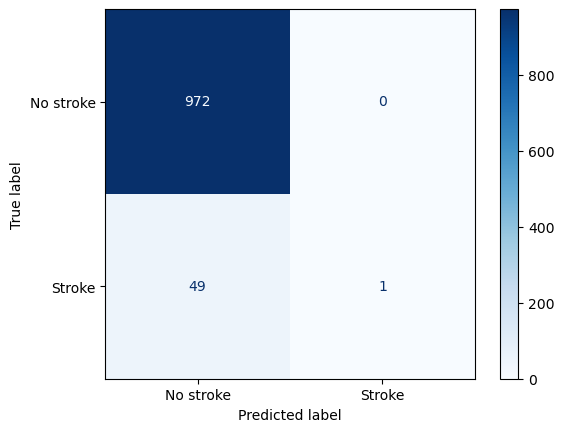

In [12]:
# Task 2: Default Logistic Regression on the scaled data, with its confusion matrix.
lr = LogisticRegression(random_state=SEED, max_iter=1000)
lr_m = evaluate_model(lr, X_train_sc, y_train, X_test_sc, y_test)
display(pd.DataFrame({"Dummy": dummy_m, "Logistic Regression": lr_m}).T.round(4))

cm = confusion_matrix(y_test, lr.predict(X_test_sc))
ConfusionMatrixDisplay(cm, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues")
plt.show()


In [13]:
# (a) Accuracy can’t separate a model that catches 1 of 50 strokes from one that catches none, so it is misleading here.
# (b) A false negative is a stroke patient sent home as healthy. There are 49 of them. Trust recall, precision, F1, ROC AUC and
# PR AUC instead. The precision of 1.00 comes from a single prediction.

,max_depth,train_AUC,cv_AUC
0,1,0.7171,0.7317
1,2,0.8208,0.8168
2,3,0.8375,0.8161
3,4,0.8580,0.8180
4,5,0.8758,0.7921
5,6,0.9026,0.7585
6,7,0.9276,0.7385
7,8,0.9494,0.7138
8,9,0.9678,0.6812
9,10,0.9808,0.6414


Best depth: 4 0.818


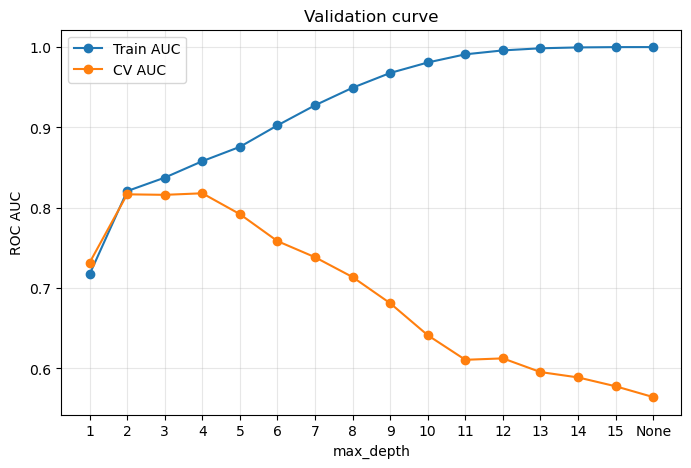

In [14]:
# Part 2 — Underfitting, Overfitting, Bias and Variance
# Task 2.1: Validation curve. Train AUC and 5-fold CV AUC for depths 1 to 15 and None.
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
train_auc, cv_auc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train, y_train)
    train_auc.append(roc_auc_score(y_train, t.predict_proba(X_train)[:, 1]))
    cv_auc.append(cross_val_score(t, X_train, y_train, cv=cv, scoring="roc_auc").mean())

labels = [str(d) for d in depths]
display(pd.DataFrame({"max_depth": labels, "train_AUC": train_auc, "cv_AUC": cv_auc}).round(4))
best = int(np.argmax(cv_auc)); print("Best depth:", labels[best], round(cv_auc[best], 4))

plt.figure(figsize=(8, 5))
plt.plot(labels, train_auc, marker="o", label="Train AUC")
plt.plot(labels, cv_auc, marker="o", label="CV AUC")
plt.xlabel("max_depth"); plt.ylabel("ROC AUC"); plt.title("Validation curve")
plt.legend(); plt.grid(alpha=0.3); plt.show()

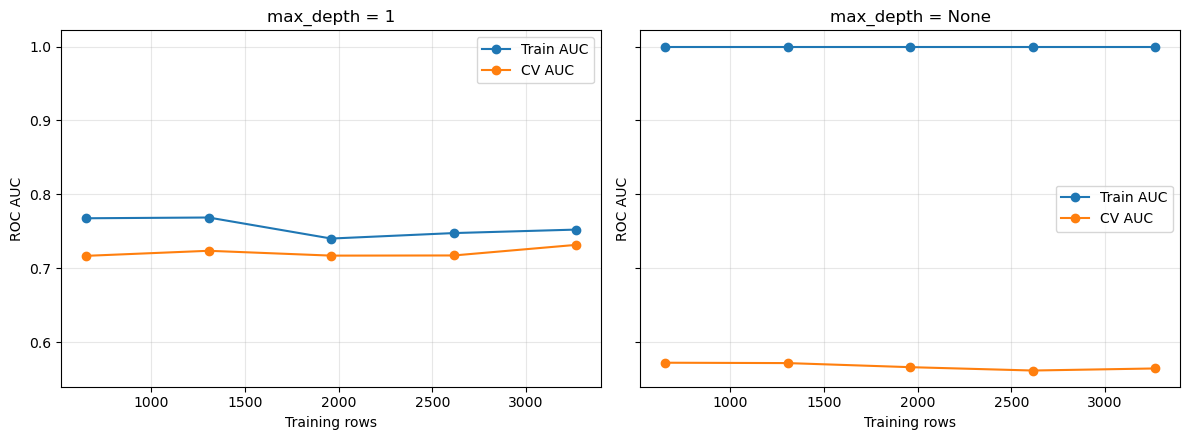

In [15]:
# Task 2.2: Learning curves for depth 1 and depth None, side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, d in zip(axes, [1, None]):
    sizes, trs, vas = learning_curve(DecisionTreeClassifier(max_depth=d, random_state=SEED),
                                     X_train, y_train, train_sizes=np.linspace(0.2, 1.0, 5),
                                     cv=cv, scoring="roc_auc")
    ax.plot(sizes, trs.mean(axis=1), marker="o", label="Train AUC")
    ax.plot(sizes, vas.mean(axis=1), marker="o", label="CV AUC")
    ax.set_title(f"max_depth = {d}"); ax.set_xlabel("Training rows"); ax.set_ylabel("ROC AUC")
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [16]:
# Task 2.3: Measure variance directly. 40 bootstrap trees per depth.
rng = np.random.default_rng(SEED)
rows = []
for d in [1, 3, None]:
    probs = np.zeros((40, len(X_test))); aucs = []
    for b in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        t = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        t.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[b] = t.predict_proba(X_test)[:, 1]
        aucs.append(roc_auc_score(y_test, probs[b]))
    rows.append({"max_depth": str(d), "mean variance": probs.var(axis=0).mean(),
                 "mean single-tree AUC": np.mean(aucs),
                 "AUC of averaged prediction": roc_auc_score(y_test, probs.mean(axis=0))})
display(pd.DataFrame(rows).round(4))

,max_depth,mean variance,mean single-tree AUC,AUC of averaged prediction
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7964,0.8343
2,None,0.0420,0.5552,0.7566


In [17]:
# a. Validation curve: depth 1 has train 0.717 and CV 0.732 (underfit). Depth 4 has train 0.858 and CV 0.818, the best.
# Depth None has train 1.000 and CV 0.564 (overfit). Depths 2 and 3 are almost as good as 4.
# (b) High bias means both curves are low and close (depth 1: about 0.75 vs 0.72), and more rows won’t help. High variance 
# means a big gap (depth None: 1.0 vs about 0.56), and more rows narrow it somewhat but don’t fix it.
# (c) Variance is 0.0007 (depth 1), 0.0017 (depth 3) and 0.0420 (depth None). Averaging helps most for depth None:
# single-tree AUC 0.555 rises to 0.757. This is what Random Forest does.
# (d) Simple models are stable but wrong (bias). Complex models fit the data but change with new data (variance).
# Depth 1 is high bias, depth None is high variance, and depth 3 is near the balance.

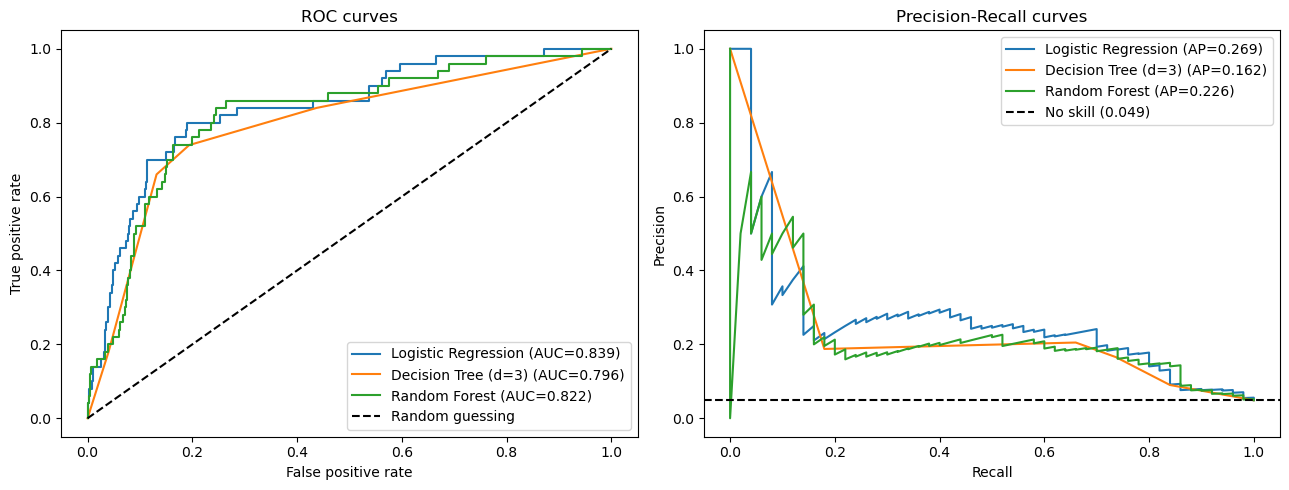

In [18]:
# Part 3 — ROC, AUC, Precision-Recall and Thresholds
# Task 3.1: Compare models with curves.
lr = LogisticRegression(random_state=SEED, max_iter=1000).fit(X_train_sc, y_train)
dt = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1).fit(X_train, y_train)

probs_test = {"Logistic Regression": lr.predict_proba(X_test_sc)[:, 1],
              "Decision Tree (d=3)": dt.predict_proba(X_test)[:, 1],
              "Random Forest": rf.predict_proba(X_test)[:, 1]}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probs_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    a1.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    a2.plot(rc, pr, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
a1.plot([0, 1], [0, 1], "k--", label="Random guessing")
a1.set_xlabel("False positive rate"); a1.set_ylabel("True positive rate"); a1.set_title("ROC curves"); a1.legend()
a2.axhline(y_test.mean(), color="k", linestyle="--", label=f"No skill ({y_test.mean():.3f})")
a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title("Precision-Recall curves"); a2.legend()
plt.tight_layout(); plt.show()

In [19]:
# Task 3.2: Choose a threshold. Use out-of-fold training probabilities, find the highest threshold with recall ≥ 0.80, 
# then apply it to the test set.
oof = cross_val_predict(LogisticRegression(random_state=SEED, max_iter=1000),
                        X_train_sc, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
THRESH = thr[np.where(rec[:-1] >= 0.80)[0]].max()
print("Chosen threshold:", round(THRESH, 4))

p_lr = probs_test["Logistic Regression"]
pred = (p_lr >= THRESH).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print("Recall:", round(recall_score(y_test, pred), 3), "| Precision:", round(precision_score(y_test, pred), 3))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))
print("Flagged:", pred.sum(), "| False alarms:", fp)

Chosen threshold: 0.0509
Recall: 0.82 | Precision: 0.135
Confusion matrix:
 [[709 263]
 [  9  41]]
Flagged: 304 | False alarms: 263


In [20]:
# (a) AUC measures ranking across all thresholds. The model ranks strokes higher, but its highest test probability is only 
# about 0.54, so the 0.5 cutoff flags almost nobody.
# (b) PR is more informative: ROC includes the many true negatives and looks flattering, while PR is judged against the
# 0.049 no-skill line.
# (c) The price is about 6 false alarms per real stroke found (263 vs 41). For: a missed stroke is far worse. Against: heavy
# follow-up cost and workload, and patient anxiety.

In [21]:
# Part 4 — Undersampling, Oversampling and SMOTE
# Task 4.1: Compare the methods. One table for Logistic Regression (scaled) and Random Forest (original)
def make_lr(**k): return LogisticRegression(random_state=SEED, max_iter=1000, **k)
def make_rf(**k): return RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                random_state=SEED, n_jobs=-1, **k)
samplers = {"none": None, "class_weight": "cw",
            "undersample": RandomUnderSampler(random_state=SEED),
            "oversample": RandomOverSampler(random_state=SEED),
            "SMOTE": SMOTE(random_state=SEED)}

rows = []
for mname, make, Xa, Xb in [("LR", make_lr, X_train_sc, X_test_sc), ("RF", make_rf, X_train, X_test)]:
    for sname, s in samplers.items():
        if s is None:    model, Xr, yr = make(), Xa, y_train
        elif s == "cw":  model, Xr, yr = make(class_weight="balanced"), Xa, y_train
        else:            model = make(); Xr, yr = s.fit_resample(Xa, y_train)   # TRAIN only
        m = evaluate_model(model, Xr, yr, Xb, y_test)
        rows.append({"Model | method": f"{mname} | {sname}", "Train rows": len(yr),
                     "Train strokes": int(yr.sum()),
                     **{k: m[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}})
table4 = pd.DataFrame(rows).round(4); display(table4)

,Model | method,Train rows,Train strokes,Precision,Recall,F1,ROC AUC,PR AUC
0,LR | none,4087,199,1.0000,0.02,0.0392,0.8394,0.2692
1,LR | class_weight,4087,199,0.1347,0.80,0.2305,0.8395,0.2595
2,LR | undersample,398,199,0.1246,0.82,0.2164,0.8352,0.2338
3,LR | oversample,7776,3888,0.1333,0.80,0.2286,0.8385,0.2646
4,LR | SMOTE,7776,3888,0.1338,0.80,0.2292,0.8406,0.2876
5,RF | none,4087,199,0.0000,0.00,0.0000,0.8224,0.2255
6,RF | class_weight,4087,199,0.2143,0.30,0.2500,0.8109,0.2088
7,RF | undersample,398,199,0.1050,0.84,0.1867,0.8203,0.2030
8,RF | oversample,7776,3888,0.1882,0.32,0.2370,0.8111,0.1906
9,RF | SMOTE,7776,3888,0.1266,0.20,0.1550,0.7668,0.1187


In [22]:
# Task 4.2: The classic mistake. SMOTE on all the data first, then split.
X_all = X.fillna(X.median())                       # SMOTE needs no missing values
X_s, y_s = SMOTE(random_state=SEED).fit_resample(X_all, y)   # WRONG ORDER
Xa, Xb, ya, yb = train_test_split(X_s, y_s, test_size=0.2, stratify=y_s, random_state=SEED)
wrong = evaluate_model(make_rf(), Xa, ya, Xb, yb)

right = table4[table4["Model | method"] == "RF | SMOTE"].iloc[0]
display(pd.DataFrame([
    {"Order": "Wrong (SMOTE then split)", **{k: wrong[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}},
    {"Order": "Correct (split then SMOTE)", **{k: right[k] for k in ["Precision", "Recall", "F1", "ROC AUC", "PR AUC"]}},
]).round(4))

,Order,Precision,Recall,F1,ROC AUC,PR AUC
0,Wrong (SMOTE then split),0.9290,0.9424,0.9356,0.9811,0.9761
1,Correct (split then SMOTE),0.1266,0.2000,0.1550,0.7668,0.1187


In [23]:
# (a) For Logistic Regression, recall jumps from 0.02 to about 0.80, precision falls to about 0.13, and ROC AUC barely 
# moves (0.835 to 0.841). Rebalancing mostly shifts the decision boundary, much like lowering the threshold, and doesn’t
# improve ranking.
# (b) Random Forest reacted differently. Most methods raised its recall only to 0.20 to 0.32, and SMOTE lowered its AUCs
# (ROC 0.767, PR 0.119), while Logistic Regression’s AUCs stayed flat. A likely reason is that deep trees memorise duplicated
# or synthetic points.
# (c) The wrong-order Random Forest scores ROC AUC 0.981, recall 0.942 and precision 0.929, against the correct 0.767, 0.20 and
# 0.127. SMOTE builds synthetic patients from real ones, so near-copies of test patients end up in training and the model has
# effectively seen the test data. Real information leaks from the test rows into training, so the numbers can’t be trusted.
# (d) I’d pick class_weight='balanced' with Logistic Regression: it is simple, throws away no data, adds no synthetic rows 
# and gives recall 0.80. Undersampling discards 95% of the data, and SMOTE adds complexity and risk.

,Logistic Regression,Tree d=3,Tree d=None,Random Forest
0.00,0.8394,0.7956,0.5797,0.8224
0.05,0.8242,0.7991,0.5339,0.7998
0.10,0.8101,0.8068,0.5437,0.7805
0.20,0.7963,0.7643,0.5418,0.7058


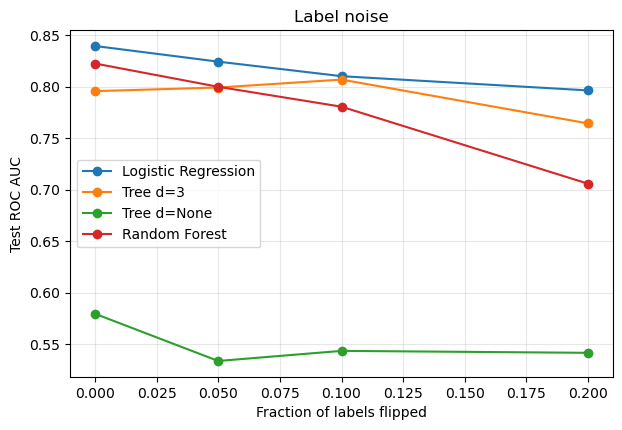

In [24]:
# Part 5 — Noisy Data
# Task 5.1: Label noise.
rng = np.random.default_rng(SEED)
def flip_labels(y, frac, rng):
    y = np.array(y, copy=True); n = int(round(frac * len(y)))
    if n:
        idx = rng.choice(len(y), n, replace=False); y[idx] = 1 - y[idx]
    return y

models = {"Logistic Regression": (lambda: make_lr(), True),
          "Tree d=3": (lambda: DecisionTreeClassifier(max_depth=3, random_state=SEED), False),
          "Tree d=None": (lambda: DecisionTreeClassifier(random_state=SEED), False),
          "Random Forest": (lambda: make_rf(), False)}

label_res = {}
for f in [0, 0.05, 0.10, 0.20]:
    reps = 1 if f == 0 else 5; label_res[f] = {}
    for name, (mk, scaled) in models.items():
        a = []
        for _ in range(reps):
            yn = flip_labels(y_train, f, rng)
            Xa, Xb = (X_train_sc, X_test_sc) if scaled else (X_train, X_test)
            a.append(roc_auc_score(y_test, mk().fit(Xa, yn).predict_proba(Xb)[:, 1]))
        label_res[f][name] = np.mean(a)
label_df = pd.DataFrame(label_res).T.round(4); display(label_df)
label_df.plot(marker="o", figsize=(7, 4.5), xlabel="Fraction of labels flipped", ylabel="Test ROC AUC",
              title="Label noise"); plt.grid(alpha=0.3); plt.show()

,Logistic Regression,Tree d=3,Tree d=None,Random Forest
0.0,0.8394,0.7956,0.5797,0.8224
0.5,0.8326,0.8011,0.5516,0.8170
1.0,0.8115,0.7763,0.5473,0.7724
2.0,0.7700,0.6988,0.5210,0.7405


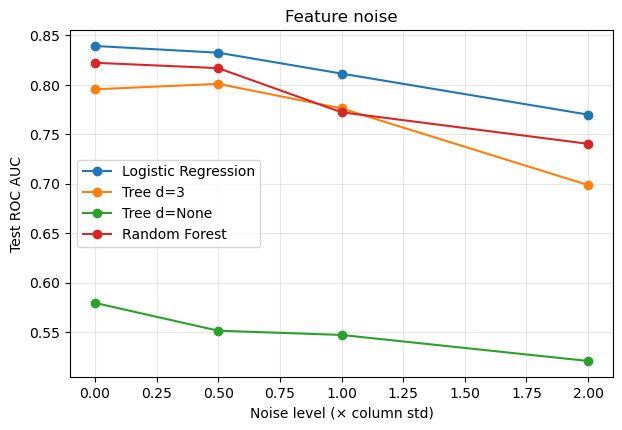

In [25]:
# Task 5.2: Feature noise.
noisy_cols = ["age", "avg_glucose_level", "bmi"]
feat_res = {}
for lvl in [0, 0.5, 1, 2]:
    reps = 1 if lvl == 0 else 5; feat_res[lvl] = {}
    for name, (mk, scaled) in models.items():
        a = []
        for _ in range(reps):
            Xn = X_train.copy()
            for c in noisy_cols:
                Xn[c] = Xn[c] + rng.normal(size=len(Xn)) * X_train[c].std() * lvl
            if scaled:
                s2 = StandardScaler().fit(Xn)          # scaler fitted on the NOISY train
                Xa, Xb = s2.transform(Xn), s2.transform(X_test)
            else:
                Xa, Xb = Xn, X_test
            a.append(roc_auc_score(y_test, mk().fit(Xa, y_train).predict_proba(Xb)[:, 1]))
        feat_res[lvl][name] = np.mean(a)
feat_df = pd.DataFrame(feat_res).T.round(4); display(feat_df)
feat_df.plot(marker="o", figsize=(7, 4.5), xlabel="Noise level (× column std)", ylabel="Test ROC AUC",
             title="Feature noise"); plt.grid(alpha=0.3); plt.show()

In [26]:
# Task 5.3: SMOTE and noisy labels. 10% flipped, 3 draws, SMOTE applied after the noise.
res = []
for mname, mk, Xa0, Xb in [("LR", make_lr, X_train_sc, X_test_sc), ("RF", make_rf, X_train, X_test)]:
    for use_smote in [False, True]:
        pr, ro = [], []
        for _ in range(3):
            yn = pd.Series(flip_labels(y_train, 0.10, rng), index=Xa0.index)
            Xa, ya = (SMOTE(random_state=SEED).fit_resample(Xa0, yn)) if use_smote else (Xa0, yn)
            p = mk().fit(Xa, ya).predict_proba(Xb)[:, 1]
            pr.append(average_precision_score(y_test, p)); ro.append(roc_auc_score(y_test, p))
        res.append({"Model": mname, "SMOTE": use_smote, "PR AUC": np.mean(pr), "ROC AUC": np.mean(ro)})
display(pd.DataFrame(res).round(4))

,Model,SMOTE,PR AUC,ROC AUC
0,LR,False,0.2412,0.8154
1,LR,True,0.2048,0.8065
2,RF,False,0.1894,0.7843
3,RF,True,0.0634,0.6097


In [27]:
# (a) At 20% label noise, Random Forest drops the most (0.822 to 0.706, about -0.117). Tree d=3 (-0.031) and Logistic Regression
# (-0.043) are the most stable. The unlimited tree is already near chance (0.58 to 0.54), which fits Part 2: it memorises the 
# training data, wrong labels included.
# (b) It depends on the model. Logistic Regression loses more from level-2 feature noise (-0.069) than from 20% label noise 
# (-0.043), while Random Forest loses more from label noise (-0.117 vs -0.082). Say that the levels aren’t strictly comparable.
# (c) With 10% noisy labels, SMOTE lowered both models. Logistic Regression went from PR AUC 0.241 to 0.205, and Random
# Forest from 0.189 to 0.063 (ROC AUC 0.784 to 0.610). SMOTE builds new points around “minority” samples, so wrongly flipped
# samples get copied into many synthetic points and the noise is amplified.

In [28]:
# Part 6 — Final Decision and Conclusion 
# Task 1: Final table. Default threshold 0.5 against the chosen threshold, using Logistic Regression.
def summarize(name, pred):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"Choice": name, "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
            "False alarms": fp, "Missed strokes": fn}

final = pd.DataFrame([summarize("LR, threshold 0.5", (p_lr >= 0.5).astype(int)),
                      summarize(f"LR, threshold {THRESH:.3f}", (p_lr >= THRESH).astype(int))])
display(final.round(4))

,Choice,Precision,Recall,F1,False alarms,Missed strokes
0,"LR, threshold 0.5",1.0000,0.02,0.0392,0,49
1,"LR, threshold 0.051",0.1349,0.82,0.2316,263,9


In [29]:
# Task 2: Executive Summary

# I chose Logistic Regression (scaled) with a lowered threshold of 0.051 instead of 0.5. On the test set it catches 41 of 50
# strokes (recall 0.82) with precision 0.135. The price is 263 false alarms, about 6 per stroke found, but it misses only 9
# strokes instead of 49. The median, scaler and threshold were learned from training data only, and resampling was done after 
# the split. One limitation is that the test set has only 50 strokes, so the estimates are noisy, and the threshold depends on
# the 80% recall target.

# Final Reflection

# (a) The most surprising result was 95.2% accuracy with only 2% recall, almost the same accuracy as a model that always
# predicts “no stroke”.

# (b) With one more hour, I would repeat the split several times to check how stable recall and precision are with only 50 
# test strokes.